In [1]:
import pandas as pd

pd.set_option('display.max_columns', None)

In [2]:
df = pd.read_csv('../Resources/Revised Final Dataset.csv')
df['Month_Year'] = pd.to_datetime(df['Month_Year'], errors='coerce')
df.head()

,Sector,Fruits,Vegetables,Spices,Fuel and light,Health,Month_Year
0,Rural,103.9,101.9,103.1,105.5,104.0,2013-01-01
1,Urban,102.3,102.9,101.8,105.4,104.1,2013-01-01
2,Rural+Urban,103.2,102.2,102.7,105.5,104.0,2013-01-01
3,Rural,104.0,102.4,103.1,106.2,104.4,2013-02-01
4,Urban,103.1,104.9,102.3,105.7,104.7,2013-02-01


In [3]:
df.set_index('Month_Year', inplace=True)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 453 entries, 2013-01-01 to 2025-07-01
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Sector          453 non-null    object 
 1   Fruits          453 non-null    float64
 2   Vegetables      453 non-null    float64
 3   Spices          453 non-null    float64
 4   Fuel and light  453 non-null    float64
 5   Health          453 non-null    float64
dtypes: float64(5), object(1)
memory usage: 24.8+ KB


In [5]:
col_order = ['Sector', 'Fruits', 'Vegetables', 'Spices', 'Fuel and light', 'Health']
df = df[col_order]

In [6]:
df.head()

,Sector,Fruits,Vegetables,Spices,Fuel and light,Health
Month_Year,,,,,,
2013-01-01,Rural,103.9,101.9,103.1,105.5,104.0
2013-01-01,Urban,102.3,102.9,101.8,105.4,104.1
2013-01-01,Rural+Urban,103.2,102.2,102.7,105.5,104.0
2013-02-01,Rural,104.0,102.4,103.1,106.2,104.4
2013-02-01,Urban,103.1,104.9,102.3,105.7,104.7


In [7]:
df = df[df['Sector']=='Urban'].copy()
df = df.asfreq('MS')

In [8]:
df.index.min(), df.index.max()

(Timestamp('2013-01-01 00:00:00'), Timestamp('2025-07-01 00:00:00'))

In [9]:
pd.date_range(start=df.index.min(), end=df.index.max(), freq='MS')

DatetimeIndex(['2013-01-01', '2013-02-01', '2013-03-01', '2013-04-01',
               '2013-05-01', '2013-06-01', '2013-07-01', '2013-08-01',
               '2013-09-01', '2013-10-01',
               ...
               '2024-10-01', '2024-11-01', '2024-12-01', '2025-01-01',
               '2025-02-01', '2025-03-01', '2025-04-01', '2025-05-01',
               '2025-06-01', '2025-07-01'],
              dtype='datetime64[ns]', length=151, freq='MS')

In [10]:
full_range = pd.date_range(start=df.index.min(), end=df.index.max(), freq='MS')

In [11]:
df.index

DatetimeIndex(['2013-01-01', '2013-02-01', '2013-03-01', '2013-04-01',
               '2013-05-01', '2013-06-01', '2013-07-01', '2013-08-01',
               '2013-09-01', '2013-10-01',
               ...
               '2024-10-01', '2024-11-01', '2024-12-01', '2025-01-01',
               '2025-02-01', '2025-03-01', '2025-04-01', '2025-05-01',
               '2025-06-01', '2025-07-01'],
              dtype='datetime64[ns]', name='Month_Year', length=151, freq='MS')

In [12]:
df.isna().sum()

Sector            0
Fruits            0
Vegetables        0
Spices            0
Fuel and light    0
Health            0
dtype: int64

In [13]:
df[df['Fuel and light'].isna()]['Fuel and light']
df['Fuel and light'].interpolate().loc['2019-03-01':'2019-05-01']

Month_Year
2019-03-01    128.8
2019-04-01    129.1
2019-05-01    129.4
Freq: MS, Name: Fuel and light, dtype: float64

In [14]:
df['Fuel and light'] = df['Fuel and light'].interpolate()
df['Fuel and light'].isna().sum()

0

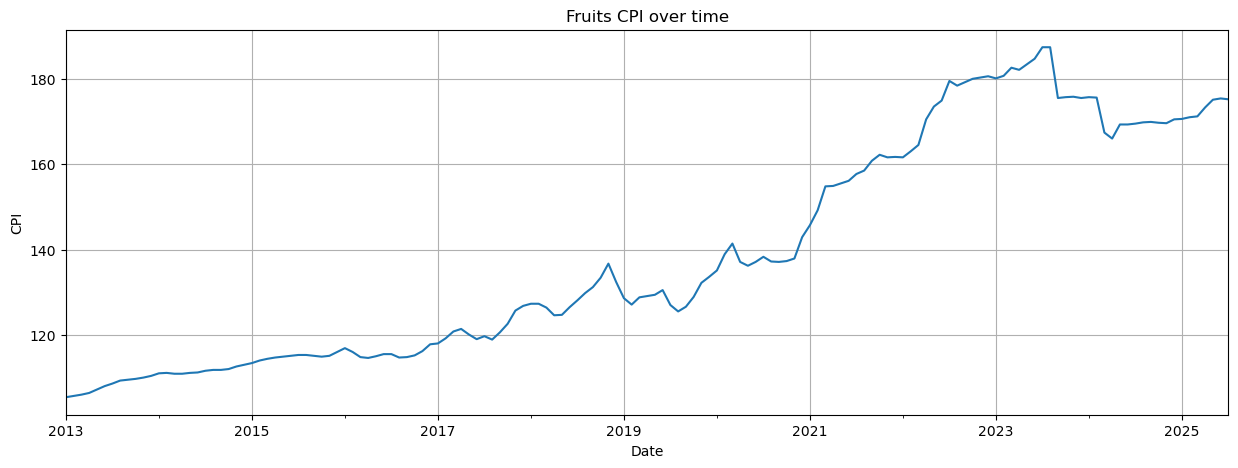

In [15]:
import matplotlib.pyplot as plt 
plt.figure(figsize=(15,5))
df['Fuel and light'].plot()
plt.title('Fruits CPI over time')
plt.xlabel('Date')
plt.ylabel('CPI')
plt.grid(True)
plt.show()

In [16]:
from statsmodels.tsa.seasonal import STL
stl = STL(df['Fuel and light'], period=12)
result = stl.fit()

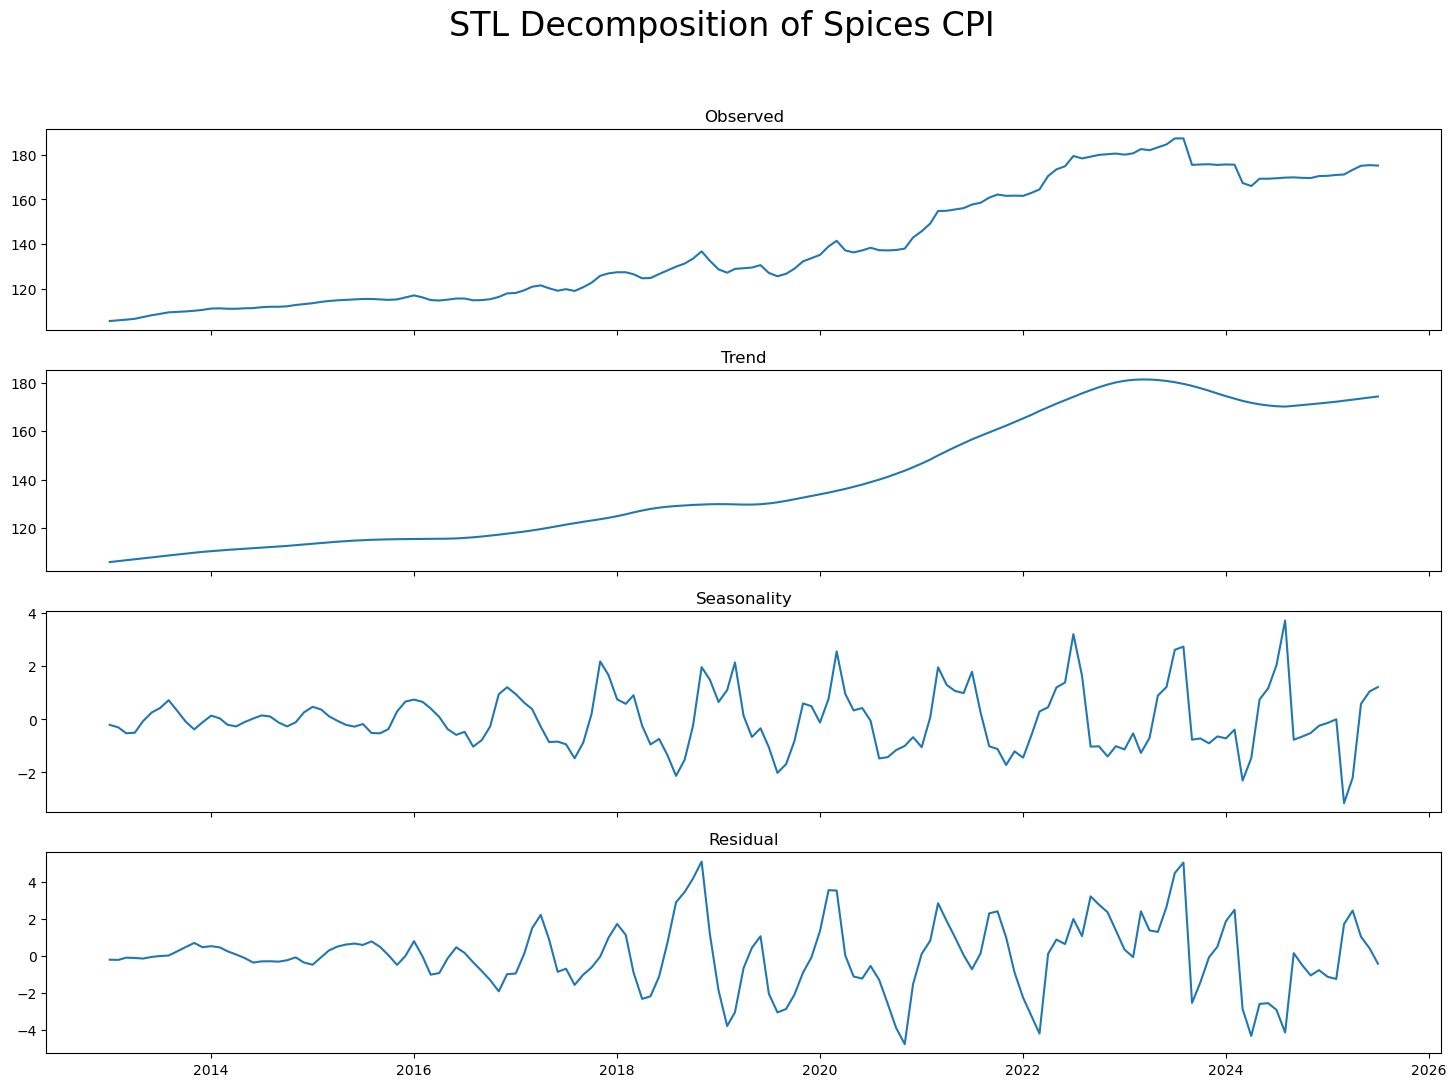

In [17]:
fig, axs = plt.subplots(4, 1, figsize=(18,12), sharex=True)

axs[0].plot(df.index, df['Fuel and light'], label='Observed')
axs[0].set_title('Observed')

axs[1].plot(df.index, result.trend, label='Trend')
axs[1].set_title('Trend')

axs[2].plot(df.index, result.seasonal, label='Seasonality')
axs[2].set_title('Seasonality')

axs[3].plot(df.index, result.resid, label='Residual')
axs[3].set_title('Residual')

plt.suptitle('STL Decomposition of Spices CPI', fontsize=24)
plt.show()

In [18]:
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(df['Fuel and light'])
adf_result

(-0.5026750097105419,
 0.891493428365552,
 1,
 149,
 {'1%': -3.4750180242954167,
  '5%': -2.8811408028842043,
  '10%': -2.577221358046935},
 576.4846612881217)

In [19]:
adf_result[0]

-0.5026750097105419

In [20]:
adf_result[1]

0.891493428365552

In [21]:
#cannot reject null hypothesis as 0.92428 > 0.05

In [22]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

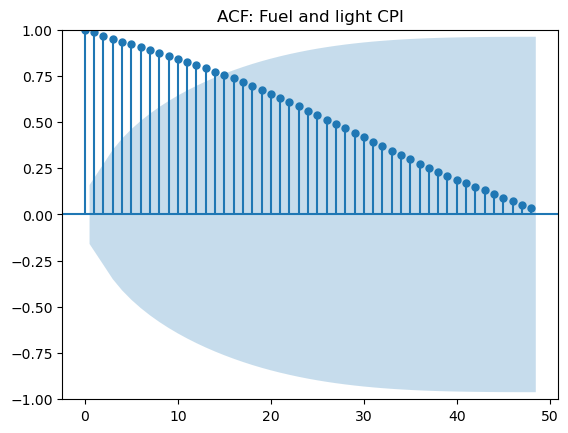

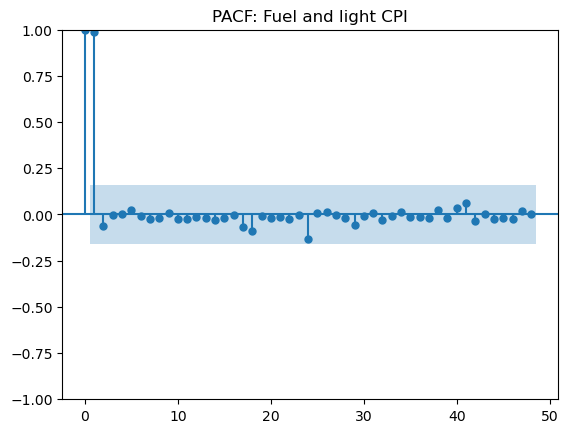

In [23]:
plot_acf(df['Fuel and light'], lags=48)
plt.title('ACF: Fuel and light CPI')
plt.show()

plot_pacf(df['Fuel and light'], lags=48)
plt.title('PACF: Fuel and light CPI')
plt.show()

In [24]:
# AR from PACF: sharp drop is from lag 1
# MA from ACF: lags 1 to 8 are significant 

In [25]:
test_size = 12 
train = df['Fuel and light'].iloc[0:-test_size]
test = df['Fuel and light'].iloc[-test_size:]

In [26]:
from statsmodels.tsa.arima.model import ARIMA

In [27]:
model = ARIMA(train, order=(0,2,1), seasonal_order=(0,1,1,12))
results = model.fit()

results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                    SARIMAX Results                                     
========================================================================================
Dep. Variable:                   Fuel and light   No. Observations:                  139
Model:             ARIMA(0, 2, 1)x(0, 1, 1, 12)   Log Likelihood                -284.126
Date:                          Sun, 22 Nov 2026   AIC                            574.251
Time:                                  15:23:52   BIC                            582.736
Sample:                              01-01-2013   HQIC                           577.698
                                   - 07-01-2024                                         
Covariance Type:                            opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.8958      0.041    -21.595      0.000      -0.977      -0.815
ma.S.L12      -0.8361      0.126     -6.643      0.000      -1.083      -0.589
sigma2         4.8430      0.295     16.418      0.000       4.265       5.421
===================================================================================
Ljung-Box (L1) (Q):                   4.58   Jarque-Bera (JB):               728.33
Prob(Q):                              0.03   Prob(JB):                         0.00
Heteroskedasticity (H):              20.87   Skew:                            -2.04
Prob(H) (two-sided):                  0.00   Kurtosis:                        14.10
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

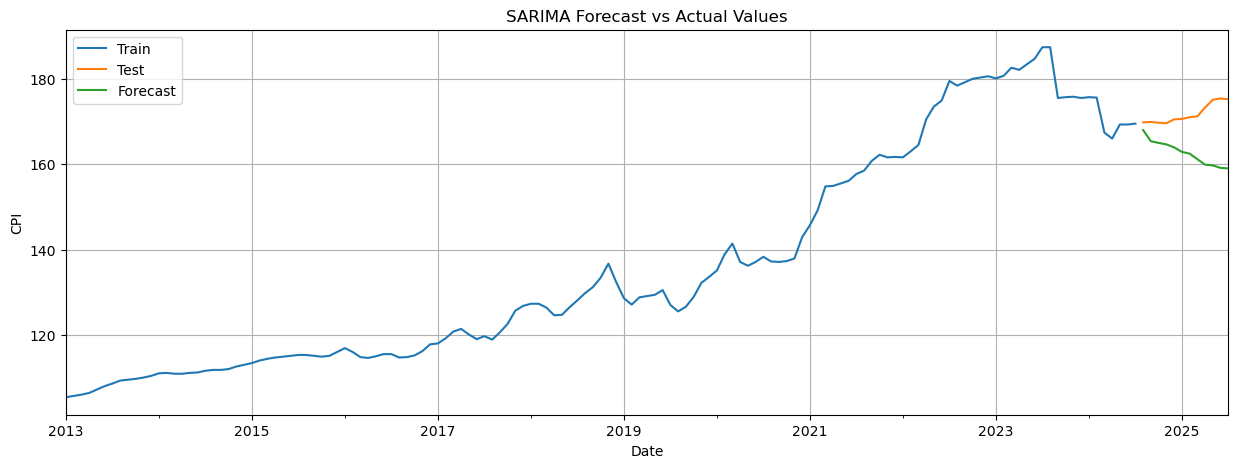

In [28]:
sarima_forecast = results.forecast(steps=test_size)

plt.figure(figsize=(15, 5))

train.plot(label='Train')
test.plot(label='Test')

sarima_forecast.index = test.index
sarima_forecast.plot(label='Forecast')

plt.title('SARIMA Forecast vs Actual Values')
plt.xlabel('Date')
plt.ylabel('CPI')
plt.legend()
plt.grid(True)

plt.show()

In [29]:
import numpy as np
from sklearn.metrics import mean_squared_error

rmse = mean_squared_error(test, sarima_forecast)
tmse = np.sqrt(rmse)
tmse

10.37360376664626

In [30]:
s = 12

p_values = [0, 1, 2]
d_values = [1]
q_values = [0, 1, 2]

P_values = [0, 1, 2]
D_values = [1]
Q_values = [0, 1, 2]

In [31]:
param_grid = [((p, d, q), (P, D, Q, s))
 for p in p_values
 for d in d_values
 for q in q_values
 for P in P_values
 for D in D_values
 for Q in Q_values]

len(param_grid)

81

In [32]:
from sklearn.model_selection import TimeSeriesSplit

In [33]:
X = df['Fuel and light']
tscv = TimeSeriesSplit(n_splits=3, test_size=12)
tscv

TimeSeriesSplit(gap=0, max_train_size=None, n_splits=3, test_size=12)

In [34]:
len(list(tscv.split(X)))

3

In [35]:
list(tscv.split(X))

[(array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
          13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
          26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
          39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,
          52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,
          65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,
          78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,
          91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103,
         104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114]),
  array([115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126])),
 (array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
          13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
          26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
          39,  40,  41,  42,  43,  44,  45,  46,

In [36]:
from tqdm import tqdm

metrics = []

for order, seasonal_order in tqdm(param_grid):
    split_rmse = []

    for train_idx, test_idx in tscv.split(X):
        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]

        model = ARIMA(X_train, order=order, seasonal_order=seasonal_order)
        results = model.fit()

        X_pred = results.forecast(steps=len(X_test))
        rmse = np.sqrt(mean_squared_error(X_test, X_pred))
        split_rmse.append(rmse)

    mean_rmse = np.mean(split_rmse)
    std_rmse = np.std(split_rmse)

    metrics.append(
        {'order': order,
         'seasonal_order': seasonal_order,
         'rmse_mean': mean_rmse,
         'rmse_std': std_rmse}
    )

  0%|          | 0/81 [00:00<?, ?it/s]

/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


 32%|███▏      | 26/81 [01:03<02:14,  2.45s/it]

/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


 32%|███▏      | 26/81 [01:20<02:14,  2.45s/it]

... (20 outputs left out)

 96%|█████████▋| 78/81 [04:31<00:10,  3.57s/it]

/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


100%|██████████| 81/81 [04:42<00:00,  3.49s/it]

In [37]:
metrics_df = pd.DataFrame(metrics)
metrics_df

,order,seasonal_order,rmse_mean,rmse_std
0,"(0, 1, 0)","(0, 1, 0, 12)",14.256580,4.783761
1,"(0, 1, 0)","(0, 1, 1, 12)",8.296244,8.498076
2,"(0, 1, 0)","(0, 1, 2, 12)",8.790671,7.132511
3,"(0, 1, 0)","(1, 1, 0, 12)",13.548534,5.125372
4,"(0, 1, 0)","(1, 1, 1, 12)",8.782142,7.286089
...,...,...,...,...
76,"(2, 1, 2)","(1, 1, 1, 12)",9.202956,7.095352
77,"(2, 1, 2)","(1, 1, 2, 12)",8.672003,7.162397
78,"(2, 1, 2)","(2, 1, 0, 12)",13.159118,6.792043
79,"(2, 1, 2)","(2, 1, 1, 12)",8.854060,7.123618


In [38]:
metrics_df.sort_values(by='rmse_mean', ascending=True)

,order,seasonal_order,rmse_mean,rmse_std
1,"(0, 1, 0)","(0, 1, 1, 12)",8.296244,8.498076
8,"(0, 1, 0)","(2, 1, 2, 12)",8.349856,7.422288
7,"(0, 1, 0)","(2, 1, 1, 12)",8.430924,7.521740
71,"(2, 1, 1)","(2, 1, 2, 12)",8.485294,7.502795
5,"(0, 1, 0)","(1, 1, 2, 12)",8.545030,7.220816
...,...,...,...,...
18,"(0, 1, 2)","(0, 1, 0, 12)",14.572248,4.299016
36,"(1, 1, 1)","(0, 1, 0, 12)",14.600019,4.271849
63,"(2, 1, 1)","(0, 1, 0, 12)",14.660811,6.032305
72,"(2, 1, 2)","(0, 1, 0, 12)",14.663985,5.979208


In [39]:
model = ARIMA(train, order=(0,1,0), seasonal_order=(0,1,1,12))
results = model.fit()

results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                     SARIMAX Results                                      
==========================================================================================
Dep. Variable:                     Fuel and light   No. Observations:                  139
Model:             ARIMA(0, 1, 0)x(0, 1, [1], 12)   Log Likelihood                -284.325
Date:                            Sun, 22 Nov 2026   AIC                            572.651
Time:                                    15:28:36   BIC                            578.323
Sample:                                01-01-2013   HQIC                           574.955
                                     - 07-01-2024                                         
Covariance Type:                              opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.S.L12      -0.9974      6.077     -0.164      0.870     -12.908      10.913
sigma2         4.2431     25.597      0.166      0.868     -45.926      54.412
===================================================================================
Ljung-Box (L1) (Q):                   8.77   Jarque-Bera (JB):               767.42
Prob(Q):                              0.00   Prob(JB):                         0.00
Heteroskedasticity (H):              23.70   Skew:                            -1.97
Prob(H) (two-sided):                  0.00   Kurtosis:                        14.43
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

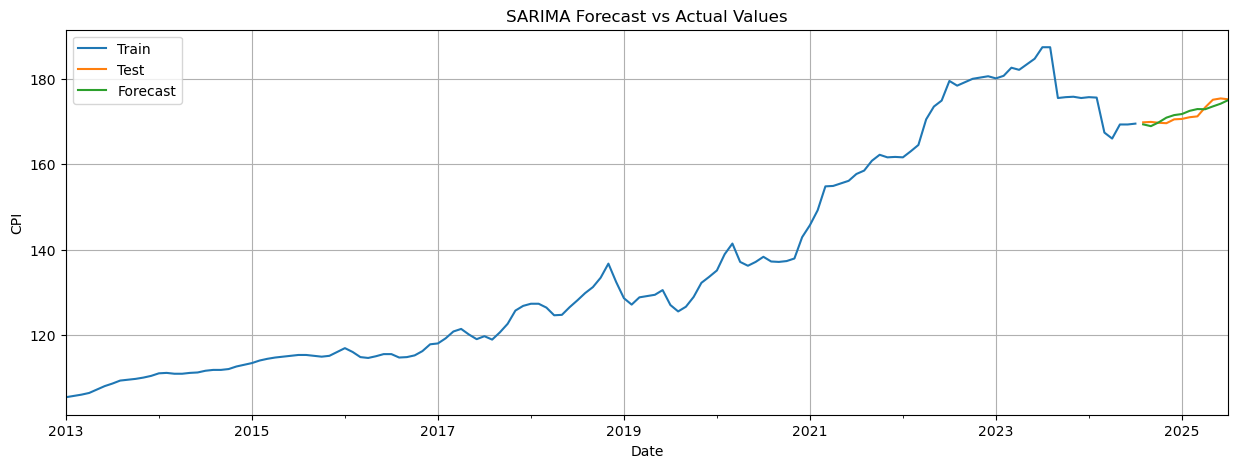

In [40]:
sarima_forecast = results.forecast(steps=test_size)

plt.figure(figsize=(15, 5))

train.plot(label='Train')
test.plot(label='Test')

sarima_forecast.index = test.index
sarima_forecast.plot(label='Forecast')

plt.title('SARIMA Forecast vs Actual Values')
plt.xlabel('Date')
plt.ylabel('CPI')
plt.legend()
plt.grid(True)

plt.show()

In [41]:
import numpy as np
from sklearn.metrics import mean_squared_error

rmse = mean_squared_error(test, sarima_forecast)
tmse = np.sqrt(rmse)
tmse

1.1011191511673128

In [42]:
results = model.fit()


import joblib
joblib.dump(results, 'Fuel and light-urban.pkl')

['Fuel and light-urban.pkl']